# Machine Learning e Data Science com Python de A À Z - IA Expert Academy

### Importação de Bibliotecas Básicas

> !pip install plotly\
> !pip install plotly --upgrade

In [1]:
# Bibliotecas
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import plotly.express as px

### Dataset: Credit Risk
Link: https://www.kaggle.com/datasets/laotse/credit-risk-dataset

In [10]:
dataset = pd.read_csv('credit_data.csv')

### Visualização dos Dados

In [11]:
dataset.head()

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1


In [12]:
dataset.tail()

,clientid,income,age,loan,default
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0
1999,2000,69436.579552,56.152617,7378.833599,0


In [13]:
dataset.tail(8)

,clientid,income,age,loan,default
1992,1993,30803.806165,23.250084,623.024153,0
1993,1994,54421.410155,26.821928,3273.631823,0
1994,1995,24254.700791,37.751622,2225.284643,0
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0
1999,2000,69436.579552,56.152617,7378.833599,0


#### Estatísticas
- Contagem: count
- Média: mean
- Desvio padrão: std
- Valor minímo: min
- Valor máximo: max

In [14]:
dataset.describe()

,clientid,income,age,loan,default
count,2000.000000,2000.000000,1997.000000,2000.000000,2000.000000
mean,1000.500000,45331.600018,40.807559,4444.369695,0.141500
std,577.494589,14326.327119,13.624469,3045.410024,0.348624
min,1.000000,20014.489470,-52.423280,1.377630,0.000000
25%,500.750000,32796.459717,28.990415,1939.708847,0.000000
50%,1000.500000,45789.117313,41.317159,3974.719419,0.000000
75%,1500.250000,57791.281668,52.587040,6432.410625,0.000000
max,2000.000000,69995.685578,63.971796,13766.051239,1.000000


**Maior Renda**

In [15]:
dataset[dataset['income'] >= 69995.685578]

,clientid,income,age,loan,default
422,423,69995.685578,52.719673,2084.370861,0


**Menor Dívida**

In [16]:
dataset[dataset['loan'] <= 1.377630]

,clientid,income,age,loan,default
865,866,28072.604355,54.142548,1.37763,0


### Visualização em Gráficos

**Contagem de Registros por Classe**
- 1717 clientes que pagam empréstimo
- 283 clientes que não pagam empréstimo

In [18]:
# Contagem de Registros por Classe
np.unique(dataset['default'], return_counts=True)

(array([0, 1]), array([1717,  283]))

#### Geração de Gráficos

<Axes: xlabel='default', ylabel='count'>

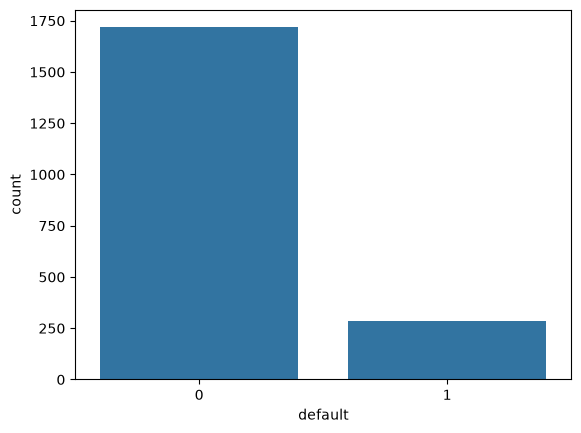

In [51]:
# Seaborn gera gráficos
sns.countplot(x = dataset['default'])

**Histograma: Idade** 

(array([202., 207., 196., 209., 170., 210., 202., 217., 196., 188.]),
 array([18.05518851, 22.64684924, 27.23850998, 31.83017071, 36.42183144,
        41.01349218, 45.60515291, 50.19681364, 54.78847438, 59.38013511,
        63.97179584]),
 <BarContainer object of 10 artists>)

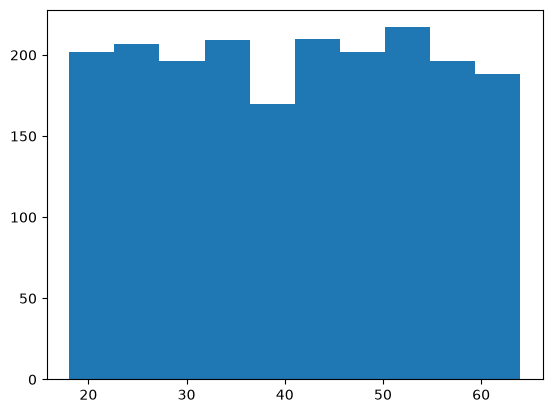

In [50]:
# Histograma
plt.hist(x = dataset['age'])

**Histograma: Renda**
- **Valor mínimo:** 20k/ano
- **Valor máximo:** ~70k/ano\
A minoria ganha próximo de 40k por ano, enquanto a maioria possui a faixa salarial entre 60k e 70k por ano.

(array([189., 198., 199., 179., 204., 209., 206., 199., 219., 198.]),
 array([20014.48947005, 25012.60908088, 30010.7286917 , 35008.84830253,
        40006.96791336, 45005.08752419, 50003.20713501, 55001.32674584,
        59999.44635667, 64997.5659675 , 69995.68557832]),
 <BarContainer object of 10 artists>)

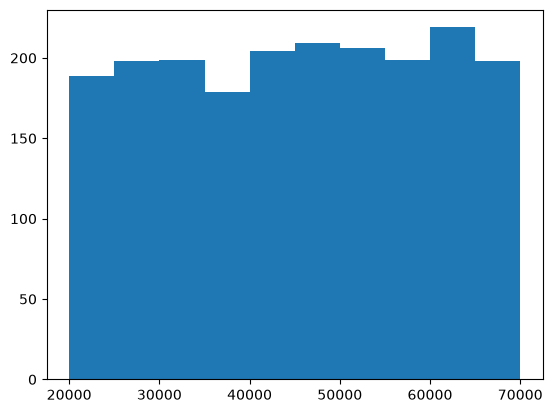

In [49]:
plt.hist(x = dataset['income'])

**Histograma: Empréstimo**
- A maioria (+350 pessoas) possuem dívidas próximas de R$ 2,000 e R$ 3,000. 
- A minoria (menos de 50 pessoas) possui dívidas entre R$ 12,000 a R$ 14,000.

(array([345., 373., 318., 277., 266., 171., 104.,  89.,  40.,  17.]),
 array([1.37762959e+00, 1.37784499e+03, 2.75431235e+03, 4.13077971e+03,
        5.50724707e+03, 6.88371443e+03, 8.26018180e+03, 9.63664916e+03,
        1.10131165e+04, 1.23895839e+04, 1.37660512e+04]),
 <BarContainer object of 10 artists>)

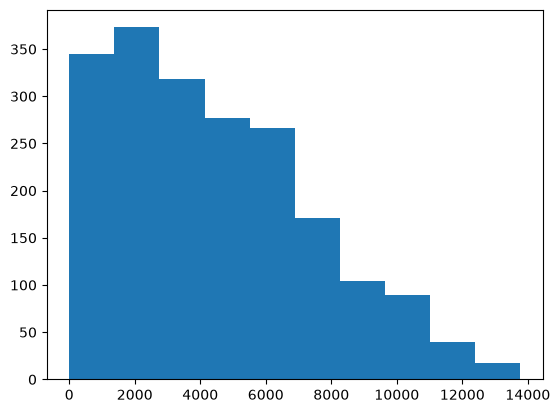

In [48]:
plt.hist(x = dataset['loan'])

#### Gráficos Dinâmicos

In [47]:
grafico = px.scatter_matrix(dataset, dimensions=['age', 'income'])
grafico.show()

- Amarelo: pessoas que não pagam empréstimo
- Azul: pessoas que pagam empréstimo

In [46]:
grafico = px.scatter_matrix(dataset, dimensions=['age', 'income', 'loan'], color='default')
grafico.show()

## Normalização do Dataset

### Tratamento de Valores Inconsistentes

#### Valores Negativos
- **loc:** localização de registros

In [27]:
dataset.loc[dataset['age'] < 0]

,clientid,income,age,loan,default
15,16,50501.726689,-28.218361,3977.287432,0
21,22,32197.620701,-52.423280,4244.057136,0
26,27,63287.038908,-36.496976,9595.286289,0


In [28]:
dataset[dataset['age'] < 0]

,clientid,income,age,loan,default
15,16,50501.726689,-28.218361,3977.287432,0
21,22,32197.620701,-52.423280,4244.057136,0
26,27,63287.038908,-36.496976,9595.286289,0


**Técnica de Tratamento 1**\
Apagar a coluna inteira (de todos os registros da base de dados).
- drop: apaga determinada coluna
- axis: 0 para índices e 1 para colunas

In [29]:
dataset_test = dataset.drop('age', axis=1)
# Sem a coluna age
dataset_test

,clientid,income,loan,default
0,1,66155.925095,8106.532131,0
1,2,34415.153966,6564.745018,0
2,3,57317.170063,8020.953296,0
3,4,42709.534201,6103.642260,0
4,5,66952.688845,8770.099235,1
...,...,...,...,...
1995,1996,59221.044874,1926.729397,0
1996,1997,69516.127573,3503.176156,0
1997,1998,44311.449262,5522.786693,1
1998,1999,43756.056605,1622.722598,0


**Técnica de Tratamento2**\
Apagar somente os registros com valores inconsistentes.

In [31]:
dataset_test2 = dataset.drop(dataset[dataset['age'] < 0].index)
dataset_test2 

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
...,...,...,...,...,...
1995,1996,59221.044874,48.518179,1926.729397,0
1996,1997,69516.127573,23.162104,3503.176156,0
1997,1998,44311.449262,28.017167,5522.786693,1
1998,1999,43756.056605,63.971796,1622.722598,0


In [32]:
# Visualização de índices
dataset.index

RangeIndex(start=0, stop=2000, step=1)

In [33]:
# Índices dos valores inconsistentes
dataset[dataset['age'] < 0].index

Index([15, 21, 26], dtype='int64')

In [34]:
# Confirmação da Remoção
dataset_test2.loc[dataset_test2['age'] < 0]

,clientid,income,age,loan,default


**Técnica de Tratamento 3 (Recomendada)**\
Preencher os valores inconsistentes manualmente.
- A remoção de dados pode prejudicar a Machine Learning, que tende a ser melhor quando há o máximo possível de dados.
- Pode não ser viável em datasets com um volume massivo de dados.

**Técnica de Tratamento 4 (Usual)**\
Preencher os valores faltantes com as médias das idades.

In [37]:
# Média dos Valores Consistentes
dataset['age'][dataset['age'] > 0].mean()

np.float64(40.92770044906149)

In [ ]:
# Os valores inconsistentes recebe a média
# dataset.loc(dataset['age'] < 0, 'age'] = 40.92

# Converte a coluna para float para aceitar valores decimais
dataset['age'] = dataset['age'].astype(float)

# Substitui os valores negativos pela média das idades válidas
dataset.loc[dataset['age'] < 0, 'age'] = dataset['age'][dataset['age'] > 0].mean()

In [45]:
dataset.head(27)

,clientid,income,age,loan,default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0
3,4,42709.534201,45.751972,6103.642260,0
4,5,66952.688845,18.584336,8770.099235,1
5,6,24904.064140,57.471607,15.498598,0
6,7,48430.359613,26.809132,5722.581981,0
7,8,24500.141984,32.897548,2971.003310,1
8,9,40654.892537,55.496853,4755.825280,0
9,10,25075.872771,39.776378,1409.230371,0
